# 🧠 Segmentación de clientes con redes neuronales (Autoencoder) + tiempos de entrega

**Versión 2 del proyecto ACA N° 1 · Grupo 19 · Especialización en IA · CUN**
Continuación del notebook `01_segmentacion_clientes_rfm.ipynb` (Machine Learning clásico).

### 🎯 Qué hacemos aquí
1. **Añadimos los tiempos de entrega** como nuevas variables del cliente (días de entrega y retraso frente a la fecha prometida).
2. **Convertimos la segmentación a redes neuronales:** un **autoencoder** (red neuronal densa no supervisada) comprime las 5 variables de cada cliente en 3 números (*espacio latente*) y las reconstruye; sobre esa **reconstrucción** (el cliente "depurado") aplicamos los mismos 3 algoritmos de clustering (K-Means, Ward, DBSCAN).
3. **Comparamos con el enfoque clásico** y explicamos paso a paso cada decisión de la red: neuronas de entrada y salida, funciones de activación y épocas de entrenamiento.

> 💡 La red está implementada **en NumPy** (propagación hacia adelante, retropropagación y optimizador Adam escritos a mano, validados con *gradient checking*). Así se entrena en segundos, se despliega en Streamlit sin librerías pesadas y se ve exactamente qué hace cada parte. Al final hay el código equivalente en PyTorch.

## 0. Configuración

In [1]:
import sys, textwrap, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data_prep import PROCESSED_PATH, load_processed
from src.neural import NN_FEATURES, FeatureTransformer, Autoencoder, NeuralSpace
from src.modeling import (SEED, DEFAULTS_NN, fit_model, fit_kmeans, fit_hierarchical, fit_dbscan,
                          evaluate_clustering, profile_segments, name_segments, recommend_action)

FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def save_fig(name): plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

df = load_processed(PROCESSED_PATH)
assert {"avg_delivery_days", "avg_delay_days"} <= set(df.columns), \
    "Falta la tabla con tiempos de entrega: ejecuta el notebook 01 o `python scripts/run_pipeline.py`."
print("Clientes:", f"{len(df):,}", "| Variables de la red:", NN_FEATURES)

Clientes: 93,357 | Variables de la red: ['recency', 'frequency', 'monetary', 'avg_delivery_days', 'avg_delay_days']


## 1. Nuevas variables: tiempos de entrega

Calculamos dos variables por cliente (promedio de sus órdenes entregadas), en `src/data_prep.py`:

| Variable | Definición | Interpretación |
|---|---|---|
| `avg_delivery_days` | fecha de entrega al cliente − fecha de compra | Qué tanto esperó el cliente |
| `avg_delay_days` | fecha de entrega real − fecha **estimada** | Negativo = llegó antes de lo prometido; positivo = llegó tarde |

Solo 8 pedidos entregados no tienen fecha de entrega; los clientes sin ningún dato se imputan con la mediana.

In [2]:
df[["avg_delivery_days", "avg_delay_days"]].describe(percentiles=[.01, .25, .5, .75, .9, .99])

,avg_delivery_days,avg_delay_days
count,"93,357.000","93,357.000"
mean,12.567,-11.151
std,9.545,10.139
min,0.533,-146.016
1%,1.836,-34.998
25%,6.788,-16.227
50%,10.234,-11.746
75%,15.717,-6.393
90%,23.087,-1.151
99%,45.961,18.842


% de clientes cuyo retraso promedio es > 0 (llegó tarde): 8.1%
Correlación de Spearman con la reseña -> días de entrega: -0.24 | retraso: -0.18


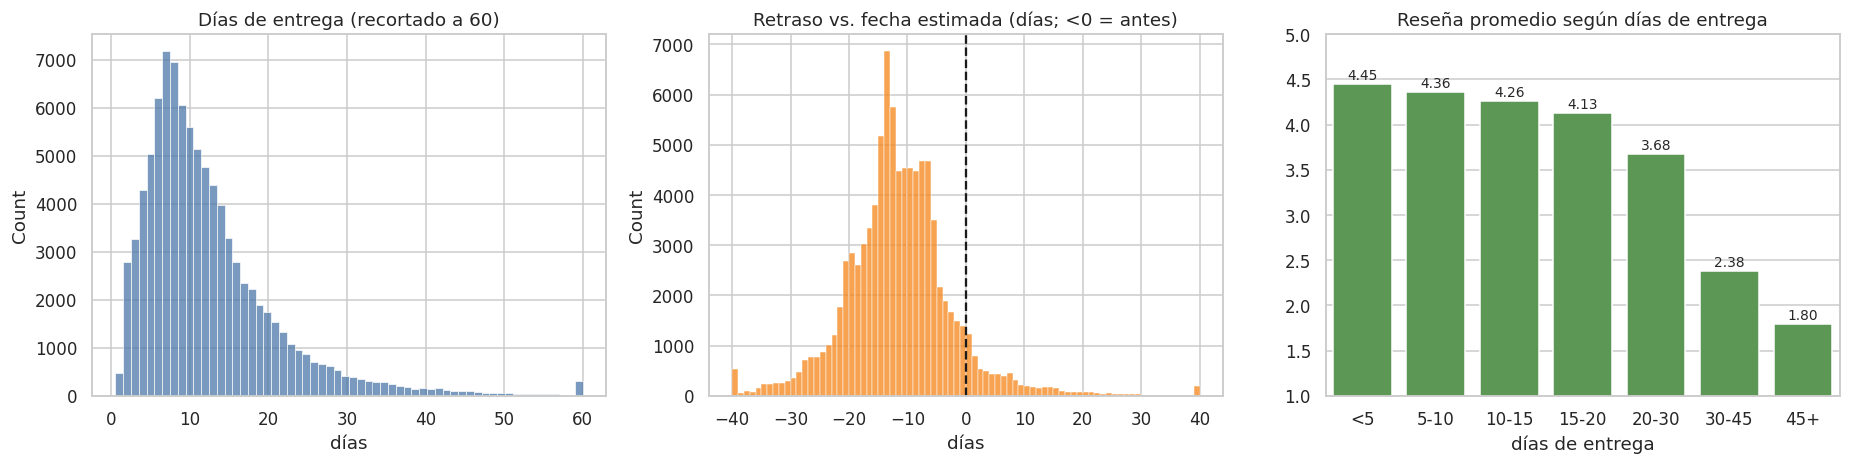

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.histplot(df["avg_delivery_days"].clip(upper=60), bins=60, ax=ax[0], color="#4c78a8")
ax[0].set_title("Días de entrega (recortado a 60)"); ax[0].set_xlabel("días")

sns.histplot(df["avg_delay_days"].clip(-40, 40), bins=80, ax=ax[1], color="#f58518")
ax[1].axvline(0, color="k", ls="--"); ax[1].set_title("Retraso vs. fecha estimada (días; <0 = antes)"); ax[1].set_xlabel("días")

bins = pd.cut(df["avg_delivery_days"], [0, 5, 10, 15, 20, 30, 45, 300], labels=["<5", "5-10", "10-15", "15-20", "20-30", "30-45", "45+"])
rev = df.groupby(bins, observed=True)["avg_review_score"].mean()
sns.barplot(x=rev.index.astype(str), y=rev.values, ax=ax[2], color="#54a24b")
ax[2].set_title("Reseña promedio según días de entrega"); ax[2].set_xlabel("días de entrega"); ax[2].set_ylim(1, 5)
for i, v in enumerate(rev.values): ax[2].text(i, v + .05, f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout(); save_fig("20_eda_entrega"); plt.show()

print(f"% de clientes cuyo retraso promedio es > 0 (llegó tarde): {100 * (df['avg_delay_days'] > 0).mean():.1f}%")
print("Correlación de Spearman con la reseña -> días de entrega:",
      round(df["avg_delivery_days"].corr(df["avg_review_score"], method="spearman"), 2),
      "| retraso:", round(df["avg_delay_days"].corr(df["avg_review_score"], method="spearman"), 2))

**Lectura:** la mayoría llega **antes** de lo prometido (mediana ≈ 12 días antes), pero hay una cola larga de entregas muy lentas, y **a más días de entrega, menor reseña**: de ≈4.4 (menos de 10 días) baja a ≈2.4 (30–45 días) y a ≈1.8 (más de 45 días). Esto confirma que el tiempo de entrega es una dimensión de negocio importante y distinta de R, F y M (correlaciones bajas con ellas).

## 2. Preparación de la entrada de la red (5 variables)

Una red neuronal aprende bien cuando sus entradas están en escalas comparables y sin colas extremas. Se aplica (`FeatureTransformer`):

- `log1p` en **Recencia, Frecuencia, Monetario y Días de entrega** (todas ≥ 0 y muy asimétricas).
- **Winsorización** (recorte a los percentiles 1 y 99) en el **retraso**, porque puede ser negativo (no admite log) y tiene extremos de −146 y +189 días que dominarían el entrenamiento.
- `StandardScaler` (media 0, desviación 1) en las 5.

In [4]:
ft = FeatureTransformer().fit(df)
X = ft.transform(df)
print("Forma de X (clientes x neuronas de entrada):", X.shape)
print("Percentiles usados para recortar el retraso (1% / 99%):", ft.lo_.round(1), "/", ft.hi_.round(1), "días")
print("Media tras transformar:", X.mean(0).round(6), "| Desv. estándar:", X.std(0).round(6))
print("\nAsimetría (skew) antes vs. después:")
before = df[NN_FEATURES].skew(); after = pd.Series(
    [pd.Series(X[:, i]).skew() for i in range(5)], index=NN_FEATURES)
pd.DataFrame({"antes": before, "después": after})

Forma de X (clientes x neuronas de entrada): (93357, 5)
Percentiles usados para recortar el retraso (1% / 99%): -35.0 / 18.8 días
Media tras transformar: [-0.  0.  0. -0.  0.] | Desv. estándar: [1. 1. 1. 1. 1.]

Asimetría (skew) antes vs. después:


,antes,después
recency,0.447,-1.252
frequency,11.095,6.522
monetary,9.211,0.531
avg_delivery_days,3.888,0.037
avg_delay_days,2.104,0.385


## 3. Arquitectura de la red: Autoencoder 5 → 16 → 3 → 16 → 5

Un **autoencoder** es una red neuronal que se entrena para **reproducir su propia entrada** pasando por un *cuello de botella* de pocas neuronas. Para lograrlo, la capa del cuello debe aprender un **resumen comprimido** del cliente. Ese resumen (3 números) es el **espacio latente**; lo que luego agruparemos es la **reconstrucción** que produce la red (la sección 6 explica por qué).

- **Encoder** (5 → 16 → 3): comprime.
- **Decoder** (3 → 16 → 5): reconstruye.
- No necesita etiquetas: la "respuesta correcta" es la propia entrada (aprendizaje no supervisado).

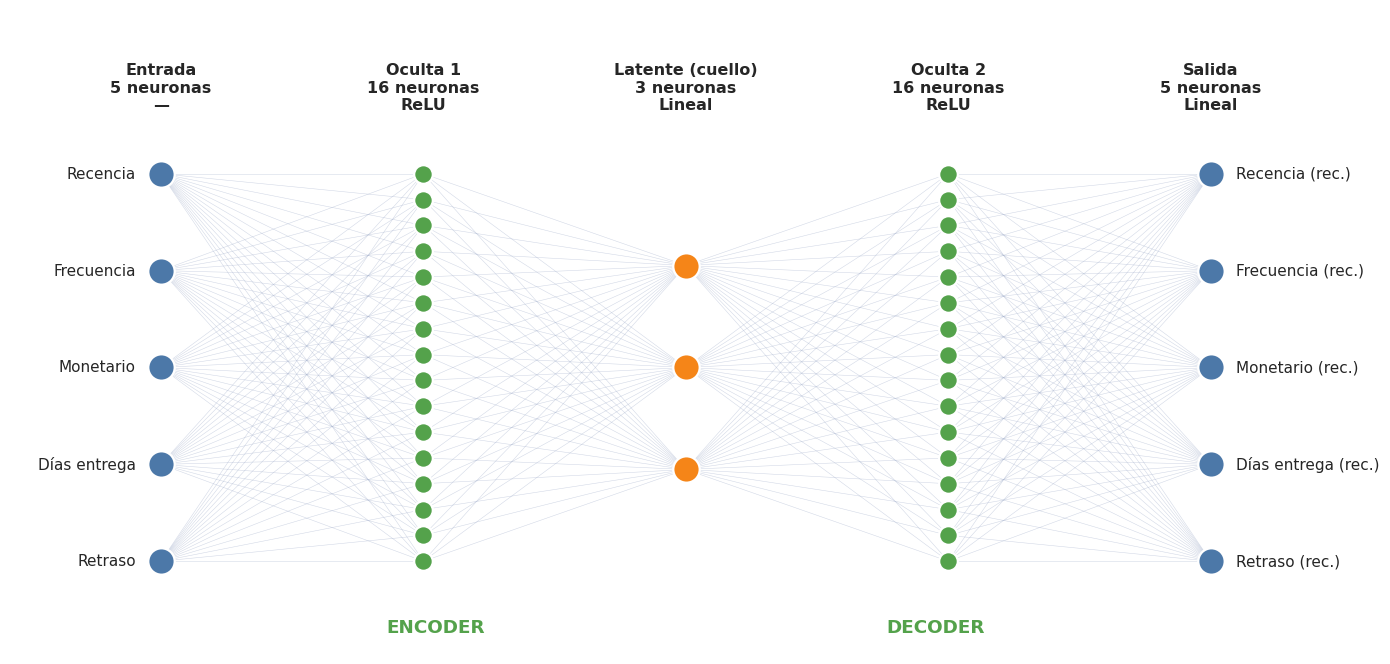

,neuronas,activación,parámetros
capa,,,
Entrada,5,—,0
Oculta 1 (encoder),16,ReLU,96
Latente (cuello de botella),3,Lineal,51
Oculta 2 (decoder),16,ReLU,64
Salida (reconstrucción),5,Lineal,85


In [5]:
def draw_network(sizes, names, acts, in_labels, out_labels):
    fig, ax = plt.subplots(figsize=(13, 6.2)); ax.axis("off")
    xs = np.linspace(0.08, 0.92, len(sizes)); pos = []
    for x, n in zip(xs, sizes):
        ys = np.linspace(0.88, 0.12, n) if n > 3 else np.linspace(0.7, 0.3, n)      # de arriba hacia abajo
        pos.append([(x, y) for y in ys])
    for l in range(len(sizes) - 1):                       # conexiones
        for (x1, y1) in pos[l]:
            for (x2, y2) in pos[l + 1]:
                ax.plot([x1, x2], [y1, y2], color="#9aa8c7", lw=.35, alpha=.45, zorder=1)
    colors = ["#4c78a8", "#54a24b", "#f58518", "#54a24b", "#4c78a8"]
    for l, pts in enumerate(pos):
        for (x, y) in pts:
            ax.scatter(x, y, s=300 if sizes[l] <= 5 else 150, color=colors[l], edgecolor="white", lw=1.5, zorder=3)
        ax.text(xs[l], 1.0, f"{names[l]}\n{sizes[l]} neuronas\n{acts[l]}", ha="center", va="bottom", fontsize=10.5, fontweight="bold")
    for (x, y), t in zip(pos[0], in_labels): ax.text(x - .02, y, t, ha="right", va="center", fontsize=10)
    for (x, y), t in zip(pos[-1], out_labels): ax.text(x + .02, y, t, ha="left", va="center", fontsize=10)
    ax.annotate("ENCODER", (0.30, -0.02), ha="center", fontsize=12, color="#54a24b", fontweight="bold")
    ax.annotate("DECODER", (0.70, -0.02), ha="center", fontsize=12, color="#54a24b", fontweight="bold")
    ax.set_xlim(-0.04, 1.04); ax.set_ylim(-0.06, 1.2)
    plt.tight_layout()

lab5 = ["Recencia", "Frecuencia", "Monetario", "Días entrega", "Retraso"]
draw_network([5, 16, 3, 16, 5], ["Entrada", "Oculta 1", "Latente (cuello)", "Oculta 2", "Salida"],
             ["—", "ReLU", "Lineal", "ReLU", "Lineal"], lab5, [t + " (rec.)" for t in lab5])
save_fig("21_arquitectura_autoencoder"); plt.show()
Autoencoder().summary()

Parámetros entrenables: 296 (pesos + sesgos) para entrenar con 93,357 clientes


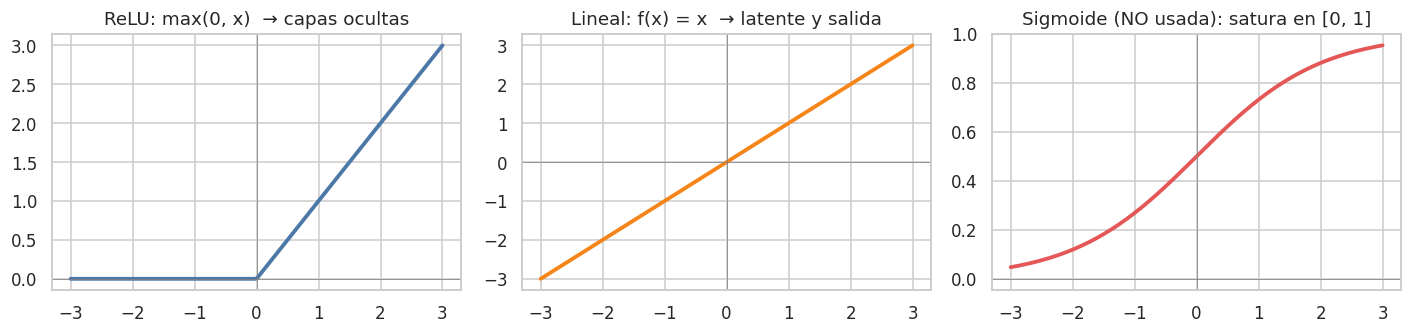

In [6]:
print("Parámetros entrenables:", Autoencoder().n_params, "(pesos + sesgos) para entrenar con", f"{len(df):,}", "clientes")
x = np.linspace(-3, 3, 200)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=False)
ax[0].plot(x, np.maximum(0, x), color="#4c78a8", lw=2.5); ax[0].set_title("ReLU: max(0, x)  → capas ocultas")
ax[1].plot(x, x, color="#f58518", lw=2.5); ax[1].set_title("Lineal: f(x) = x  → latente y salida")
ax[2].plot(x, 1 / (1 + np.exp(-x)), color="#e45756", lw=2.5); ax[2].set_title("Sigmoide (NO usada): satura en [0, 1]")
for a in ax: a.axhline(0, color="gray", lw=.5); a.axvline(0, color="gray", lw=.5)
plt.tight_layout(); save_fig("22_funciones_activacion"); plt.show()

## 4. ¿Por qué estos tamaños? Decisiones basadas en experimentos

Cada decisión se justifica con una medición. Usamos como criterio el **error de reconstrucción (MSE) en un 10% de clientes de validación** que la red nunca ve al entrenar (menor = mejor). Como las variables están estandarizadas (varianza 1), `1 − MSE` equivale aproximadamente a la **fracción de información que la red logra conservar**.

### 4.1 Tamaño del cuello de botella (neuronas latentes)
Se compara con **PCA** (la técnica lineal equivalente) con el mismo número de dimensiones.

In [7]:
rows = []
for L in [1, 2, 3, 4]:
    a = Autoencoder(5, 16, L, seed=SEED).fit(X, seed=SEED)
    p = PCA(L).fit(X); mse_pca = float(((p.inverse_transform(p.transform(X)) - X) ** 2).mean())
    rows.append({"neuronas latentes": L, "MSE validación (autoencoder)": a.history["best_val_loss"],
                 "MSE (PCA lineal)": mse_pca, "info conservada AE": f"{100 * (1 - a.history['best_val_loss']):.1f}%",
                 "info conservada PCA": f"{100 * (1 - mse_pca):.1f}%"})
pd.DataFrame(rows).set_index("neuronas latentes")

,MSE validación (autoencoder),MSE (PCA lineal),info conservada AE,info conservada PCA
neuronas latentes,,,,
1,0.318,0.713,68.2%,28.7%
2,0.132,0.478,86.8%,52.2%
3,0.046,0.264,95.4%,73.6%
4,0.000,0.095,100.0%,90.5%


- Con **1–2** neuronas se pierde demasiada información. Con **4** casi no hay compresión (la red "copia" la entrada: 5 → 4 es poco resumen).
- Con **3** neuronas el autoencoder conserva mucho más que PCA con 3 componentes (la red captura relaciones **no lineales**), comprime 40% y permite **graficar el espacio latente en 3D**. → **Latente = 3.**

### 4.2 Neuronas de las capas ocultas
Se repite cada configuración con 3 inicializaciones distintas (semillas) para no depender de la suerte.

In [8]:
rows = []
for H in [4, 8, 16, 32]:
    r = []
    for s in range(3):
        a = Autoencoder(5, H, 3, seed=s).fit(X, seed=s); r.append((a.history["best_val_loss"], a.history["best_epoch"]))
    r = np.array(r)
    rows.append({"neuronas ocultas": H, "parámetros": Autoencoder(5, H, 3).n_params, "MSE val. (media)": r[:, 0].mean(),
                 "MSE val. (desv.)": r[:, 0].std(), "mejor época (media)": r[:, 1].mean()})
pd.DataFrame(rows).set_index("neuronas ocultas")

,parámetros,MSE val. (media),MSE val. (desv.),mejor época (media)
neuronas ocultas,,,,
4,80,0.111,0.006,31.667
8,152,0.065,0.004,56.333
16,296,0.045,0.002,92.667
32,584,0.040,0.003,76.000


Pasar de 4 a 8 y de 8 a 16 neuronas **reduce claramente el error**; de 16 a 32 la mejora es pequeña (≈0.045 → ≈0.040) a cambio de casi el doble de parámetros. → **16 neuronas ocultas**: es el punto donde empiezan los rendimientos decrecientes.

### 4.3 Tasa de aprendizaje (learning rate)

In [9]:
rows = []
for lr in [1e-3, 3e-3, 1e-2]:
    r = []
    for s in range(3):
        a = Autoencoder(5, 16, 3, seed=s).fit(X, lr=lr, seed=s); r.append((a.history["best_val_loss"], a.history["best_epoch"]))
    r = np.array(r)
    rows.append({"learning rate": lr, "MSE val. (media)": r[:, 0].mean(), "MSE val. (desv.)": r[:, 0].std(),
                 "mejor época (media)": r[:, 1].mean()})
pd.DataFrame(rows).set_index("learning rate")

,MSE val. (media),MSE val. (desv.),mejor época (media)
learning rate,,,
0.001,0.045,0.003,140.000
0.003,0.045,0.002,92.667
0.010,0.044,0.003,49.333


Los tres valores alcanzan prácticamente el mismo error de validación (≈0.045, dentro de la variabilidad entre semillas de ±0.003): la diferencia está en la **velocidad**. `lr = 0.001` necesita ≈140 épocas, `lr = 0.01` ≈50 y `lr = 0.003` ≈90. Elegimos **lr = 0.003** (Adam) como valor intermedio y conservador: converge sin necesitar muchas épocas y evita los pasos grandes de 0.01, que pueden provocar oscilaciones en la curva de validación. **Lotes de 256** clientes.

## 5. Entrenamiento final y número de épocas

Una **época** es una pasada completa por los datos de entrenamiento (≈ 84,000 clientes en ≈ 330 lotes de 256). En lugar de fijar un número de épocas "a ojo", usamos **parada temprana (early stopping)**:

- Se permite un **máximo de 300 épocas**.
- Tras cada época se mide el error en el 10% de validación.
- Si el error de validación **no mejora durante 10 épocas seguidas** (*paciencia*), se detiene y se **restauran los pesos de la mejor época**.

época   1 | pérdida 0.2816 | validación 0.1450
época  20 | pérdida 0.0676 | validación 0.0685
época  40 | pérdida 0.0594 | validación 0.0597
época  60 | pérdida 0.0547 | validación 0.0555
época  80 | pérdida 0.0517 | validación 0.0521
época 100 | pérdida 0.0491 | validación 0.0509
época 120 | pérdida 0.0473 | validación 0.0483
época 140 | pérdida 0.0458 | validación 0.0465
época 160 | pérdida 0.0444 | validación 0.0474

Entrenamiento: 7.8 s | épocas ejecutadas: 161 | mejor época: 151 | MSE validación (mejor): 0.0456


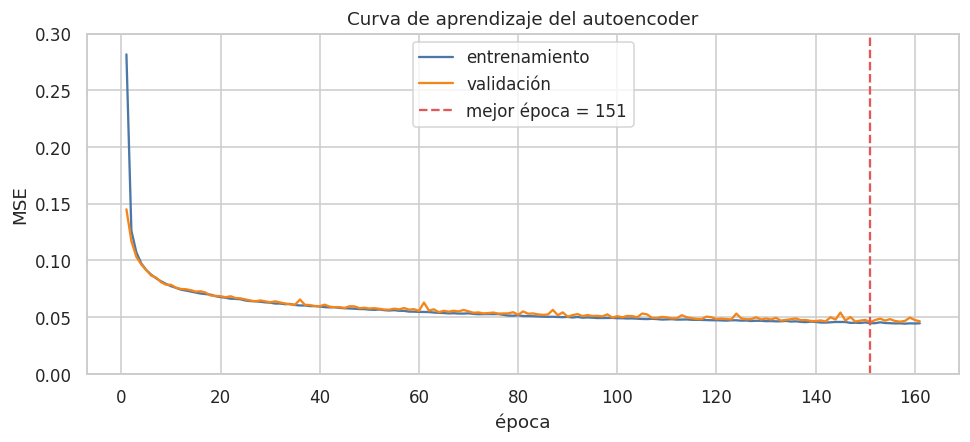

In [10]:
t0 = time.time()
ae = Autoencoder(n_features=5, hidden=16, latent=3, seed=SEED).fit(X, epochs=300, batch_size=256, lr=3e-3,
                                                                    patience=10, seed=SEED, verbose=20)
h = ae.history
print(f"\nEntrenamiento: {time.time() - t0:.1f} s | épocas ejecutadas: {h['epochs_run']} | mejor época: {h['best_epoch']} "
      f"| MSE validación (mejor): {h['best_val_loss']:.4f}")

plt.figure(figsize=(9, 4.2))
plt.plot(range(1, h["epochs_run"] + 1), h["loss"], label="entrenamiento", color="#4c78a8")
plt.plot(range(1, h["epochs_run"] + 1), h["val_loss"], label="validación", color="#f58518")
plt.axvline(h["best_epoch"], color="#e45756", ls="--", label=f"mejor época = {h['best_epoch']}")
plt.ylim(0, 0.3); plt.xlabel("época"); plt.ylabel("MSE"); plt.title("Curva de aprendizaje del autoencoder")
plt.legend(); plt.tight_layout(); save_fig("23_curva_aprendizaje"); plt.show()

In [11]:
# ¿Qué tan bien reconstruye cada variable? (MSE por variable, 0 = perfecto; 1 = no mejor que predecir el promedio)
mse_var = ((ae.reconstruct(X) - X) ** 2).mean(axis=0)
p3 = PCA(3).fit(X); mse_pca_var = ((p3.inverse_transform(p3.transform(X)) - X) ** 2).mean(axis=0)
rec = pd.DataFrame({"autoencoder (3 latentes)": mse_var, "PCA (3 componentes)": mse_pca_var}, index=NN_FEATURES)
print(rec.round(3).to_string())
print(f"\nMSE global -> autoencoder: {mse_var.mean():.3f} | PCA: {mse_pca_var.mean():.3f}")

                   autoencoder (3 latentes)  PCA (3 componentes)
recency                               0.079                0.105
frequency                             0.004                0.432
monetary                              0.015                0.388
avg_delivery_days                     0.043                0.217
avg_delay_days                        0.079                0.177

MSE global -> autoencoder: 0.044 | PCA: 0.264


**Lectura de la curva:** el error baja rápido en las primeras ~10 épocas, luego mejora lentamente y se estabiliza. La validación (naranja) acompaña al entrenamiento (azul): **no hay sobreajuste** (esperable: 296 parámetros frente a ~93,000 clientes). La parada temprana detuvo el entrenamiento cuando seguir entrenando ya no aportaba, así que el número de épocas **lo decide el comportamiento de los datos** y no una cifra arbitraria.

## 6. ¿Qué espacio se agrupa? Un experimento de estabilidad (hallazgo importante)

La red produce dos representaciones de cada cliente: el **vector latente** (3 neuronas del cuello de botella) y la **reconstrucción** (5 neuronas de salida: el cliente "depurado"). Lo natural en la literatura es agrupar el espacio latente, así que lo probamos primero... y encontramos un problema.

Una red neuronal parte de pesos aleatorios, por lo que **dos entrenamientos con distinta semilla aprenden embeddings distintos**. Si los segmentos cambian mucho de un entrenamiento a otro, no son confiables. Lo medimos con el **Índice de Rand Ajustado (ARI)** entre las particiones obtenidas con distintas semillas (1 = idénticas, 0 = coincidencia al azar), entrenando 5 autoencoders y agrupando con K-Means (k = 5) **(a)** su espacio latente y **(b)** su reconstrucción. Como referencia medimos la estabilidad del K-Means clásico directo ante remuestreo bootstrap.

In [12]:
from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score as ari

N_SEEDS = 5
base = fit_kmeans(X, 5).labels                 # referencia: K-Means clásico directo sobre las 5 variables
lat, rec, rows = {}, {}, []
for s in range(N_SEEDS):
    a = Autoencoder(5, 16, 3, seed=s).fit(X, seed=s)
    lat[s] = fit_kmeans(StandardScaler().fit_transform(a.encode(X)), 5).labels       # (a) agrupar el ESPACIO LATENTE
    rec[s] = fit_kmeans(a.reconstruct(X), 5).labels                                    # (b) agrupar la RECONSTRUCCIÓN
    pl = profile_segments(df, lat[s]); top = pl["retraso_medio_dias"].idxmax()         # segmento (latente) con mayor retraso
    rows.append({"semilla": s, "mejor época": a.history["best_epoch"], "MSE val.": a.history["best_val_loss"],
                 "ARI latente vs sem. 0": ari(lat[0], lat[s]), "ARI reconstr. vs sem. 0": ari(rec[0], rec[s]),
                 "ARI reconstr. vs clásico": ari(base, rec[s]),
                 "latente: % clientes seg. más tardío": pl.loc[top, "pct_clientes"],
                 "latente: reseña de ese seg.": pl.loc[top, "review_promedio"]})
pd.DataFrame(rows).set_index("semilla")

,mejor época,MSE val.,ARI latente vs sem. 0,ARI reconstr. vs sem. 0,ARI reconstr. vs clásico,latente: % clientes seg. más tardío,latente: reseña de ese seg.
semilla,,,,,,,
0,108,0.044,1.000,1.000,0.852,20.490,3.470
1,75,0.043,0.508,0.811,0.911,4.380,1.870
2,95,0.048,0.076,0.808,0.887,71.190,4.060
3,90,0.040,0.235,0.826,0.895,8.430,4.460
4,108,0.047,0.304,0.816,0.897,5.940,2.260


In [13]:
def pairwise(d):
    v = [ari(d[i], d[j]) for i, j in combinations(range(N_SEEDS), 2)]
    return np.mean(v), np.min(v), np.max(v)

rng = np.random.RandomState(0); boot = []
for b in range(N_SEEDS):                                    # clásico: ¿cambia el K-Means si remuestreamos los clientes?
    idx = rng.choice(len(X), len(X), replace=True)
    boot.append(ari(base, KMeans(5, n_init=10, random_state=b).fit(X[idx]).predict(X)))

summary = pd.DataFrame({
    "Clásico: K-Means directo (bootstrap vs. modelo completo)": [np.mean(boot), np.min(boot), np.max(boot)],
    "Red neuronal: agrupar ESPACIO LATENTE (entre semillas)": pairwise(lat),
    "Red neuronal: agrupar RECONSTRUCCIÓN (entre semillas)": pairwise(rec)},
    index=["ARI medio", "ARI mínimo", "ARI máximo"]).T
summary.to_csv(ROOT / "reports" / "stability_nn.csv")
summary

,ARI medio,ARI mínimo,ARI máximo
Clásico: K-Means directo (bootstrap vs. modelo completo),0.969,0.960,0.981
Red neuronal: agrupar ESPACIO LATENTE (entre semillas),0.184,-0.033,0.508
Red neuronal: agrupar RECONSTRUCCIÓN (entre semillas),0.848,0.808,0.888


### Qué aprendimos
- **Agrupar el espacio latente es inestable**: el ARI entre entrenamientos es bajo, y el segmento "más tardío" cambia de tamaño y hasta de naturaleza según la semilla (en algunas semillas ni siquiera aparece un grupo con entregas lentas). Las métricas internas calculadas en ese espacio (silueta, Davies-Bouldin) **no sirven para juzgarlo**: miden qué tan bien se agrupa dentro de un embedding que se deforma de una ejecución a otra. *No es una buena base para entregar segmentos de negocio.*
- **Agrupar la reconstrucción es mucho más estable** (ARI alto entre semillas y alto frente al K-Means clásico): la reconstrucción conserva la geometría de las variables originales, así que los grupos no dependen de cómo la red "dobló" el espacio latente.
- El K-Means clásico es el más estable (ARI ≈ 0.97 al remuestrear).

> **Decisión:** usamos la red como **filtro de clientes** — la salida de 5 neuronas (cliente reconstruido a través del cuello de botella de 3) — y sobre ella aplicamos K-Means, Ward y DBSCAN. El espacio latente se conserva solo para **visualizar**.

## 7. Segmentación sobre la salida de la red (3 algoritmos)

Cada cliente pasa por el autoencoder completo y obtenemos su versión reconstruida (5 variables). Es la que agrupamos con **K-Means, Ward y DBSCAN**.

In [14]:
ns = NeuralSpace(ft, ae, StandardScaler().fit(ae.encode(X)))      # empaqueta transformador + autoencoder + escalado del latente
Xh = ns.denoise(X)                                                  # cliente "depurado": salida de la red (n, 5)
Z = ns.latent(X)                                                    # latente estandarizado (n, 3): solo para visualizar
print("Reconstrucción:", Xh.shape, "| MSE reconstrucción vs. entrada:", round(float(((Xh - X) ** 2).mean()), 4))

def both_spaces(labels):
    # Métricas en el espacio que se agrupó (reconstrucción) y en el espacio original de 5 variables (común a todos los modelos)
    a, b = evaluate_clustering(Xh, labels), evaluate_clustering(X, labels)
    return {"clusters": a["n_clusters"], "% ruido": a["noise_pct"],
            "sil. reconstr.": a["silhouette"], "DB reconstr.": a["davies_bouldin"], "CH reconstr.": a["calinski_harabasz"],
            "sil. 5 vars": b["silhouette"], "DB 5 vars": b["davies_bouldin"], "CH 5 vars": b["calinski_harabasz"]}

Reconstrucción: (93357, 5) | MSE reconstrucción vs. entrada: 0.0439


### 7.1 K-Means: elección de k

In [15]:
scan = pd.DataFrame([{"k": k, **both_spaces(fit_kmeans(Xh, k).labels)} for k in range(2, 9)]).set_index("k")
scan[["sil. reconstr.", "DB reconstr.", "CH reconstr.", "sil. 5 vars"]]

,sil. reconstr.,DB reconstr.,CH reconstr.,sil. 5 vars
k,,,,
2,0.594,0.592,"23,766.200",0.584
3,0.246,1.143,"28,380.500",0.227
4,0.278,1.112,"32,423.700",0.251
5,0.267,1.084,"34,753.800",0.240
6,0.237,1.099,"33,085.100",0.211
7,0.253,1.095,"31,616.800",0.221
8,0.236,1.163,"30,279.600",0.203


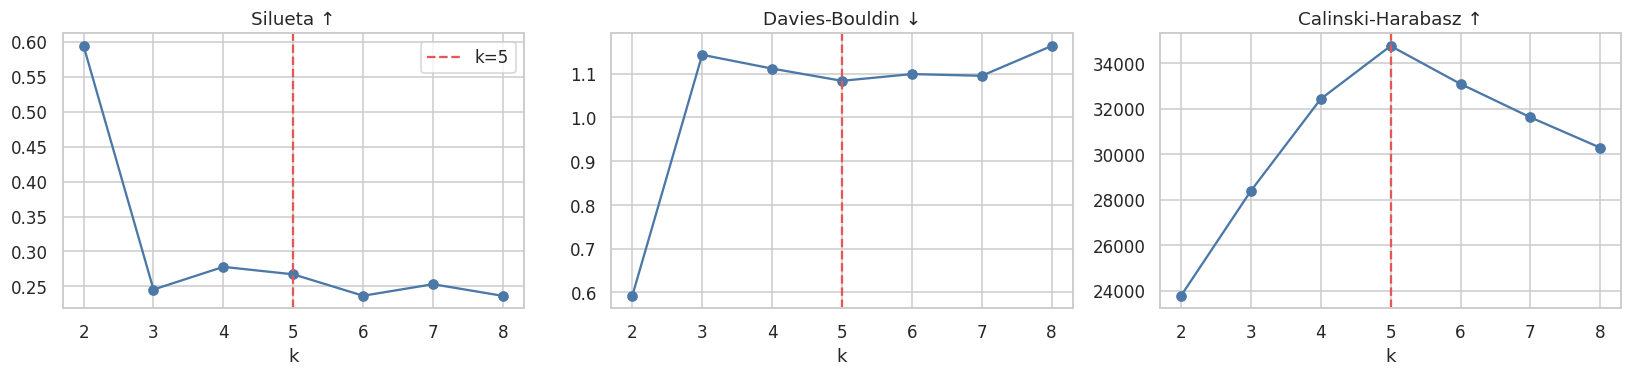

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a_, (col, t) in zip(ax, [("sil. reconstr.", "Silueta ↑"), ("DB reconstr.", "Davies-Bouldin ↓"), ("CH reconstr.", "Calinski-Harabasz ↑")]):
    a_.plot(scan.index, scan[col], marker="o", color="#4c78a8"); a_.axvline(5, color="#e45756", ls="--", label="k=5"); a_.set_title(t); a_.set_xlabel("k")
ax[0].legend(); plt.tight_layout(); save_fig("28_kmeans_k_nn"); plt.show()

**¿Por qué k = 5?** k = 2 es trivial (solo aísla a los ~2,800 clientes recurrentes). **k = 5 maximiza Calinski-Harabasz y minimiza Davies-Bouldin**, y su silueta (≈0.27) queda muy cerca de la mejor entre k ≥ 3 (k = 4: ≈0.28). Más allá de 5 solo se fragmentan grupos. (Es el mismo k que usa el K-Means clásico directo con las 5 variables, lo que permite comparar.)

In [17]:
km = fit_model("K-Means", Xh, defaults=DEFAULTS_NN)       # k = 5
print("Tamaños:", np.bincount(km.labels).tolist())

Tamaños: [25230, 17124, 33597, 2801, 14605]


### 7.2 Clustering jerárquico (Ward)

In [18]:
hc = fit_model("Jerárquico (Ward)", Xh, defaults=DEFAULTS_NN)   # k = 5, ajustado con muestra de 8,000 y extendido por centroide
print("Tamaños:", np.bincount(hc.labels).tolist())
pd.DataFrame([{"k": k, **both_spaces(fit_hierarchical(Xh, k, 8000).labels)} for k in [3, 4, 5, 6]]).set_index("k")[["sil. reconstr.", "DB reconstr.", "CH reconstr.", "sil. 5 vars"]]

Tamaños: [20236, 29150, 18334, 2801, 22836]


,sil. reconstr.,DB reconstr.,CH reconstr.,sil. 5 vars
k,,,,
3,0.257,1.084,"28,247.100",0.236
4,0.266,1.184,"31,746.200",0.237
5,0.252,1.083,"33,176.600",0.223
6,0.251,1.204,"30,785.000",0.219


### 7.3 DBSCAN
Con 93k clientes DBSCAN guarda todas las vecindades en memoria (≈ n²) y el núcleo de clientes típicos es muy denso, por lo que se **ajusta con una muestra de 20,000** (con `min_samples` reescalado para conservar la densidad) y el resto de clientes se asigna al *core point* más cercano. El espacio es de 5 dimensiones, por eso `eps` es mayor que en el proyecto clásico (3 dimensiones).

Percentiles 50/75/85/90/95: [0.286 0.397 0.476 0.545 0.676]


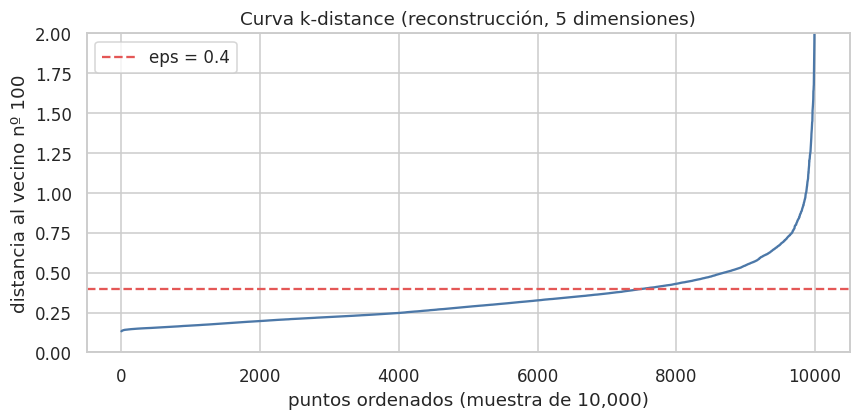

In [19]:
q = np.random.RandomState(SEED).choice(len(Xh), 10000, replace=False)
d, _ = NearestNeighbors(n_neighbors=100).fit(Xh).kneighbors(Xh[q])
kd = np.sort(d[:, -1])
plt.figure(figsize=(8, 4)); plt.plot(kd, color="#4c78a8"); plt.axhline(0.4, color="#e45756", ls="--", label="eps = 0.4")
plt.ylim(0, 2); plt.xlabel("puntos ordenados (muestra de 10,000)"); plt.ylabel("distancia al vecino nº 100"); plt.title("Curva k-distance (reconstrucción, 5 dimensiones)")
plt.legend(); plt.tight_layout(); save_fig("24_kdistance_nn"); plt.show()
print("Percentiles 50/75/85/90/95:", np.percentile(kd, [50, 75, 85, 90, 95]).round(3))

In [20]:
grid = []
for eps, ms in [(0.3, 100), (0.4, 100), (0.5, 200), (0.6, 200), (0.8, 300)]:
    m = fit_dbscan(Xh, eps, ms, sample_size=20000)
    grid.append({"eps": eps, "min_samples": ms, **both_spaces(m.labels)})
pd.DataFrame(grid).set_index(["eps", "min_samples"])[["clusters", "% ruido", "sil. reconstr.", "DB reconstr.", "sil. 5 vars"]]

,,clusters,% ruido,sil. reconstr.,DB reconstr.,sil. 5 vars
eps,min_samples,,,,,
0.300,100,8,32.030,0.012,0.740,-0.040
0.400,100,5,13.370,0.117,0.639,0.103
0.500,200,2,12.530,0.614,0.403,0.598
0.600,200,2,5.910,0.590,0.462,0.580
0.800,300,2,2.610,0.582,0.501,0.571


Elegimos **eps = 0.4, min_samples = 100**: es la combinación que mantiene varios grupos con un ruido moderado (≈13%). Con `eps` menor el ruido se dispara (≈30%) y con `eps ≥ 0.5` quedan solo 2 clusters, de modo que casi todo cae en un único grupo. Como en el proyecto clásico, DBSCAN encuentra **un núcleo masivo + microgrupos + ruido**: sirve para detectar atípicos más que para segmentar la base.

In [21]:
db = fit_model("DBSCAN", Xh, defaults=DEFAULTS_NN)
lab, cnt = np.unique(db.labels, return_counts=True); print(dict(zip(lab.tolist(), cnt.tolist())), "(-1 = ruido)")

{-1: 12482, 0: 79732, 1: 808, 2: 161, 3: 109, 4: 65} (-1 = ruido)


## 8. Evaluación y comparación con el enfoque clásico

Ahora la comparación es mucho más justa: la reconstrucción conserva la geometría de las 5 variables originales. Aun así mostramos las métricas en **ambos espacios**: "reconstr." (donde se agrupó) y "5 vars" (espacio original, común a todos los modelos). Como referencia se añade el **K-Means clásico directo** sobre las 5 variables (sin red neuronal), con k = 5. La columna **ARI vs. clásico** indica cuánto se parece cada partición a la del K-Means clásico directo.

In [22]:
b = evaluate_clustering(X, base)
rows = {"Red + K-Means (k=5)": both_spaces(km.labels),
        "Red + Ward (k=5)": both_spaces(hc.labels),
        "Red + DBSCAN": both_spaces(db.labels),
        "Clásico: K-Means directo, 5 vars (k=5)": {"clusters": b["n_clusters"], "% ruido": 0.0, "sil. reconstr.": np.nan,
                                                  "DB reconstr.": np.nan, "CH reconstr.": np.nan, "sil. 5 vars": b["silhouette"],
                                                  "DB 5 vars": b["davies_bouldin"], "CH 5 vars": b["calinski_harabasz"]}}
comp = pd.DataFrame(rows).T
comp["ARI vs. clásico"] = [ari(base, km.labels), ari(base, hc.labels), ari(base[db.labels != -1], db.labels[db.labels != -1]), 1.0]
comp.to_csv(ROOT / "reports" / "model_comparison_nn.csv")
comp

,clusters,% ruido,sil. reconstr.,DB reconstr.,CH reconstr.,sil. 5 vars,DB 5 vars,CH 5 vars,ARI vs. clásico
Red + K-Means (k=5),5.000,0.000,0.267,1.084,"34,753.800",0.240,1.167,"30,649.000",0.906
Red + Ward (k=5),5.000,0.000,0.252,1.083,"33,176.600",0.223,1.173,"29,138.900",0.691
Red + DBSCAN,5.000,13.370,0.117,0.639,"2,247.100",0.103,0.855,"2,082.100",0.016
"Clásico: K-Means directo, 5 vars (k=5)",5.000,0.000,NaN,NaN,NaN,0.244,1.159,"30,931.800",1.000


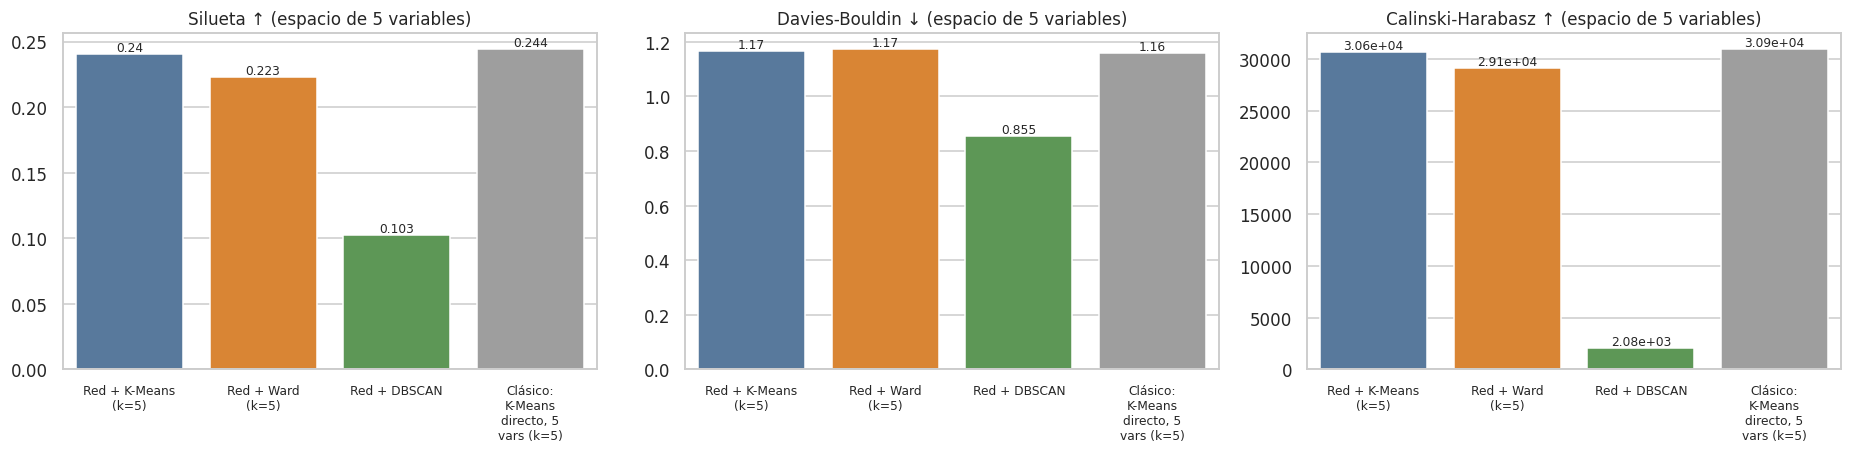

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); cols = ["#4c78a8", "#f58518", "#54a24b", "#9e9e9e"]
for a_, (col, t) in zip(ax, [("sil. 5 vars", "Silueta ↑ (espacio de 5 variables)"), ("DB 5 vars", "Davies-Bouldin ↓ (espacio de 5 variables)"), ("CH 5 vars", "Calinski-Harabasz ↑ (espacio de 5 variables)")]):
    sns.barplot(x=comp.index, y=comp[col], hue=comp.index, ax=a_, palette=cols, legend=False)
    a_.set_title(t, fontsize=11); a_.set_xlabel(""); a_.set_ylabel("")
    a_.set_xticklabels([textwrap.fill(t_.get_text(), 14) for t_ in a_.get_xticklabels()], fontsize=8)
    for p in a_.patches: a_.annotate(f"{p.get_height():,.3g}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); save_fig("25_comparacion_nn"); plt.show()

### Interpretación
- **K-Means y Ward con red** obtienen métricas prácticamente iguales a las del K-Means clásico directo (silueta ≈ 0.22–0.24 en el espacio de 5 variables). Sus particiones se parecen a la clásica: mucho en K-Means (ARI ≈ 0.91) y algo menos en Ward (≈ 0.69). Dicho de forma honesta: **en estos datos la red neuronal no mejora la segmentación, la confirma**. La estructura de los clientes es la misma tras pasar por el cuello de botella de 3 neuronas, lo que da confianza en que los segmentos reflejan patrones reales y no artefactos.
- **DBSCAN** vuelve a producir un núcleo masivo + microgrupos + ruido; sus métricas se calculan sin el ruido y no son comparables.
- Silueta ≈ 0.25 significa **fronteras difusas**: los clientes forman un continuo y no grupos naturales perfectos.
- **El aporte real de este notebook es doble:** (1) los **tiempos de entrega** como nueva dimensión de segmentación (sección 9), y (2) el **estudio de estabilidad** que muestra qué enfoque neuronal es confiable y cuál no.

## 9. Perfil de los segmentos (red + K-Means, k = 5)

In [24]:
labels = km.labels
prof = profile_segments(df, labels)
names = name_segments(prof, df, use_delivery=True)
prof["nombre"] = prof.index.map(names)
dfp = df.assign(cluster=labels, segmento=pd.Series(labels).map(names).values)
prof[["nombre", "clientes", "pct_clientes", "recencia_media", "frecuencia_media", "monetario_medio",
      "entrega_media_dias", "retraso_medio_dias", "review_promedio", "pct_ingresos"]]

,nombre,clientes,pct_clientes,recencia_media,frecuencia_media,monetario_medio,entrega_media_dias,retraso_medio_dias,review_promedio,pct_ingresos
segment,,,,,,,,,,
0,0 · Inactivos de alto valor (en riesgo),25230,27.030,266.730,1.000,310.180,11.450,-16.090,4.240,50.740
1,1 · Entrega tardía,17124,18.340,251.560,1.000,149.940,25.850,0.970,3.410,16.650
2,2 · Inactivos de ticket bajo (dormidos),33597,35.990,294.780,1.000,69.360,9.070,-14.090,4.360,15.110
3,3 · Recurrentes,2801,3.000,219.810,2.110,308.590,12.340,-11.900,4.210,5.600
4,4 · Recientes de ticket bajo,14605,15.640,41.970,1.000,125.610,7.000,-9.930,4.380,11.900


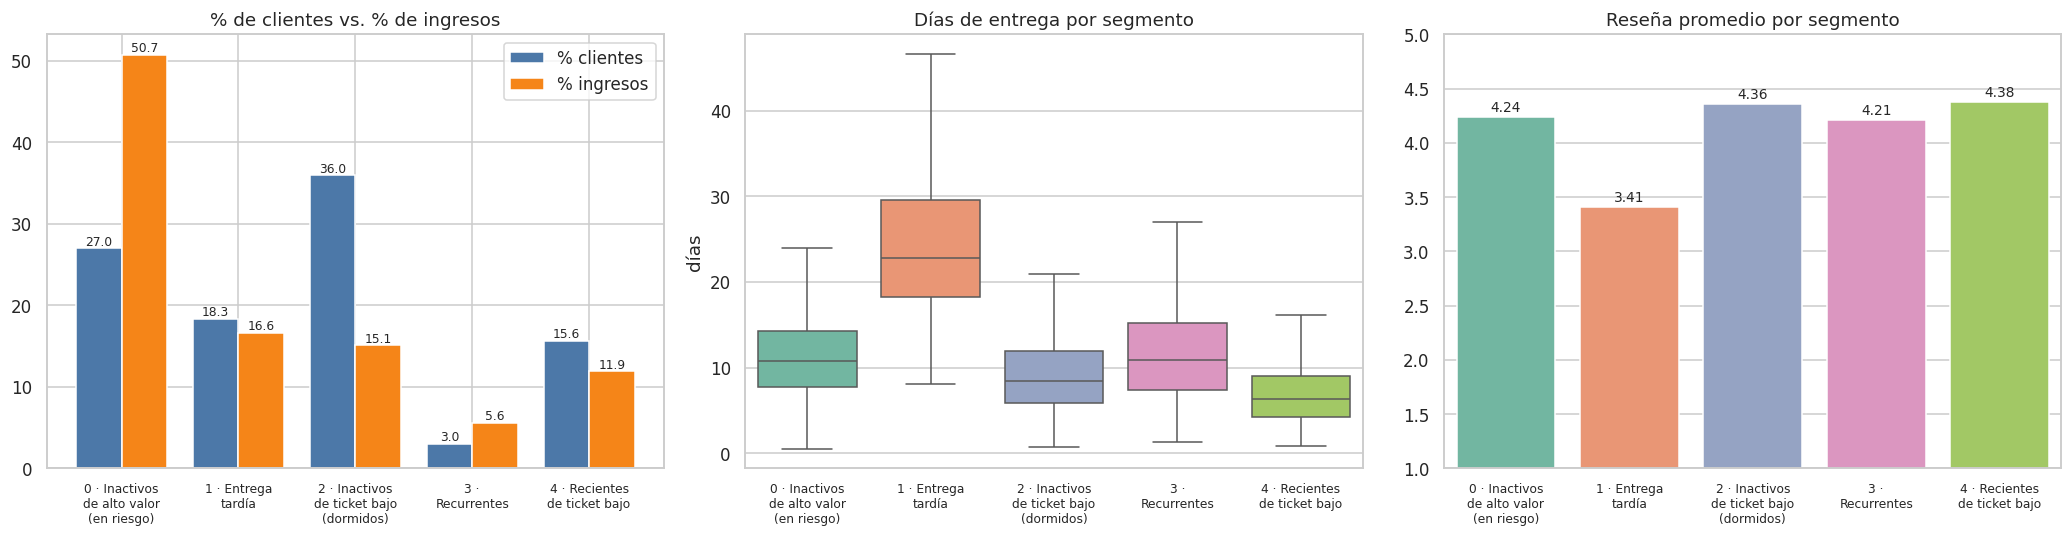

In [25]:
order = prof["nombre"].tolist()
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
share = prof.set_index("nombre")[["pct_clientes", "pct_ingresos"]]
share.index = [textwrap.fill(n, 14) for n in share.index]
share.plot(kind="bar", ax=ax[0], color=["#4c78a8", "#f58518"], width=.78); ax[0].set_title("% de clientes vs. % de ingresos")
ax[0].legend(["% clientes", "% ingresos"]); ax[0].tick_params(axis="x", rotation=0, labelsize=8); ax[0].set_xlabel("")
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.1f", fontsize=8)
sns.boxplot(data=dfp, x="segmento", y="avg_delivery_days", order=order, hue="segmento", hue_order=order, ax=ax[1], palette="Set2", showfliers=False, legend=False)
ax[1].set_title("Días de entrega por segmento"); ax[1].set_xlabel(""); ax[1].set_ylabel("días")
ax[1].set_xticklabels([textwrap.fill(t.get_text(), 14) for t in ax[1].get_xticklabels()], fontsize=8)
rv = prof.set_index("nombre")["review_promedio"]
sns.barplot(x=[textwrap.fill(n, 14) for n in rv.index], y=rv.values, hue=rv.index, ax=ax[2], palette="Set2", legend=False)
ax[2].set_title("Reseña promedio por segmento"); ax[2].set_ylim(1, 5); ax[2].set_xlabel(""); ax[2].tick_params(axis="x", labelsize=8)
for i, v in enumerate(rv.values): ax[2].text(i, v + .05, f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout(); save_fig("26_perfil_segmentos_nn"); plt.show()

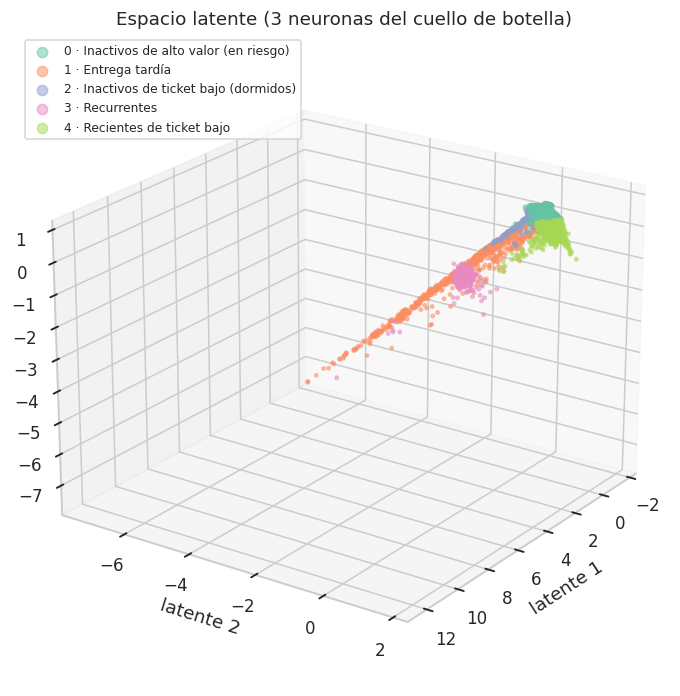

In [26]:
# Espacio latente en 3D (las 3 neuronas del cuello de botella), coloreado por los segmentos anteriores — solo para visualizar
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
idx = np.random.RandomState(SEED).choice(len(Z), 6000, replace=False)
fig = plt.figure(figsize=(8.5, 6.5)); ax3 = fig.add_subplot(111, projection="3d")
for c in sorted(prof.index):
    s_ = idx[labels[idx] == c]
    ax3.scatter(Z[s_, 0], Z[s_, 1], Z[s_, 2], s=5, alpha=.5, color=sns.color_palette("Set2")[int(c) % 8], label=names[c])
ax3.set_xlabel("latente 1"); ax3.set_ylabel("latente 2"); ax3.set_zlabel("latente 3"); ax3.view_init(22, 35)
ax3.legend(markerscale=3, fontsize=8, loc="upper left"); ax3.set_title("Espacio latente (3 neuronas del cuello de botella)")
plt.tight_layout(); save_fig("27_latente_3d"); plt.show()

In [27]:
# ¿Qué cambia al incorporar los tiempos de entrega? Comparación con el K-Means clásico de la v1 (solo RFM, k=4)
from src.modeling import prepare_features
Xr, _ = prepare_features(df)
v1 = fit_kmeans(Xr, 4).labels
print("ARI entre la segmentación RFM (v1, k=4) y la nueva con entrega y red neuronal (k=5):", round(ari(v1, km.labels), 2))
print("\nReseña promedio de los clientes según si su entrega llegó tarde (retraso promedio > 0):")
print(df.groupby(df["avg_delay_days"] > 0)["avg_review_score"].agg(["mean", "size"]).rename(index={False: "a tiempo o antes", True: "tarde"}).round(2))

ARI entre la segmentación RFM (v1, k=4) y la nueva con entrega y red neuronal (k=5): 0.53

Reseña promedio de los clientes según si su entrega llegó tarde (retraso promedio > 0):
                  mean   size
avg_delay_days               
a tiempo o antes 4.290  85808
tarde            2.560   7549


### 🧠 Hallazgos de negocio

1. **Entrega tardía** — alrededor del **18%** de los clientes: esperan ≈ 26 días y reciben el pedido, en promedio, **después de la fecha prometida**; su reseña media cae a ≈ 3.4 (frente a ≈ 4.2–4.4 de los demás segmentos). Este segmento **no existía en la versión RFM** y es el principal aporte de los tiempos de entrega. El patrón es aún más fuerte a nivel de cliente: quienes recibieron tarde dan una reseña promedio de ≈ 2.6, frente a ≈ 4.3 de quienes recibieron a tiempo o antes (última celda de código).
2. **Inactivos de alto valor (en riesgo)** — ≈ 27% de los clientes pero **≈ 51% de los ingresos**: sigue siendo la mayor oportunidad de reactivación (coincide con la versión RFM).
3. **Inactivos de ticket bajo (dormidos)** ≈ 36%, **Recientes** ≈ 16% (última compra hace ≈ 42 días) y **Recurrentes** 3% (≈ 2.1 órdenes) completan el mapa.
4. Los porcentajes pueden variar unos puntos con otra ejecución del entrenamiento, pero la estructura (el segmento de entrega tardía, los de valor y los recurrentes) **se mantiene** gracias a haber agrupado la reconstrucción (sección 6). Frente a la segmentación RFM de la v1 la coincidencia es parcial (ARI ≈ 0.53): los tiempos de entrega **reorganizan** parte de los grupos, no los reemplazan.

**Acciones sugeridas:**

In [28]:
for seg in sorted(names):
    print(f"• {names[seg]}\n    → {recommend_action(names[seg])}")

• 0 · Inactivos de alto valor (en riesgo)
    → Reactivar con prioridad: campañas personalizadas de reconquista y cupones de recompra (concentran gran parte de los ingresos).
• 1 · Entrega tardía
    → Prioridad de servicio: sus pedidos llegan después de lo prometido y su reseña es la más baja; compensar (cupón o reembolso de envío) y auditar la logística.
• 2 · Inactivos de ticket bajo (dormidos)
    → Reactivación de bajo costo: email automatizado y promociones por categoría favorita; no sobreinvertir.
• 3 · Recurrentes
    → Cuidar y recompensar: son la minoría que ya recompra; programa de puntos y comunicación frecuente.
• 4 · Recientes de ticket bajo
    → Hacer crecer el ticket: bundles, envío gratis sobre un monto y recomendaciones de productos.


## 10. Guardado de artefactos para la app

In [29]:
ns.save()                                                    # models/autoencoder.npz + models/neural_preprocessing.joblib
prof.to_csv(ROOT / "reports" / "nn_kmeans_segment_profile.csv")
print("Guardado en models/:", sorted(p.name for p in (ROOT / "models").glob("*") if p.name != ".gitkeep"))
print("Pesos del autoencoder:", {k: v.shape for k, v in ns.ae.p.items()})
print("\nLanzar la app:  streamlit run app.py   (selecciona 'Red neuronal' en la barra lateral)")

Guardado en models/: ['autoencoder.npz', 'dbscan.joblib', 'hierarchical.joblib', 'kmeans.joblib', 'neural_preprocessing.joblib', 'scaler.joblib']
Pesos del autoencoder: {'W1': (5, 16), 'b1': (16,), 'W2': (16, 3), 'b2': (3,), 'W3': (3, 16), 'b3': (16,), 'W4': (16, 5), 'b4': (5,)}

Lanzar la app:  streamlit run app.py   (selecciona 'Red neuronal' en la barra lateral)


# 📘 Explicación paso a paso de la red neuronal

## 1. ¿Qué red se usa y cómo?
Un **autoencoder denso** (perceptrón multicapa *feed-forward*, entrenado sin etiquetas) usado como **filtro de clientes**:

1. El **encoder** comprime las 5 variables de un cliente en 3 números (cuello de botella).
2. El **decoder** reconstruye las 5 variables a partir de esos 3 números.
3. Se entrena para **minimizar el error de reconstrucción**; así aprende la estructura principal de los clientes y descarta el ruido.
4. La **salida de la red** (el cliente reconstruido, 5 valores) es lo que agrupamos con **K-Means, Ward y DBSCAN** (aprendizaje no supervisado).

La red **no clasifica**: aprende una representación y los algoritmos de clustering hacen la segmentación. *(Probamos agrupar directamente las 3 neuronas latentes, pero resultó inestable entre entrenamientos; ver sección 6.)*

## 2. Neuronas de entrada: **5**
Una neurona por variable: **Recencia, Frecuencia, Monetario, Días de entrega y Retraso de entrega.**
- Se mantiene el RFM del proyecto original y se añaden los dos tiempos de entrega solicitados.
- **Por qué solo estas 5:** las reseñas y las cuotas quedan **fuera del entrenamiento a propósito**, para usarlas como *validación independiente*: si el segmento de "entrega tardía" muestra una reseña más baja sin que la red haya visto la reseña, el segmento es real.
- Días de entrega y retraso se correlacionan (ρ ≈ 0.3) pero aportan información distinta (esperar mucho vs. incumplir la promesa).
- La capa de entrada **no tiene activación ni parámetros**: recibe los datos ya transformados (log1p / winsorización / estandarización).

## 3. Capas ocultas: **16 + 16 neuronas** (ReLU)
- El experimento 4.2 mostró que 16 es donde empiezan los rendimientos decrecientes del error de reconstrucción (con 8 es claramente peor; con 32 mejora poco y casi duplica los parámetros).
- Son más que las entradas (5) para que la red construya **combinaciones no lineales** de variables antes de comprimir.

## 4. Capa latente (cuello de botella): **3 neuronas** (lineal)
- Con 3 neuronas el autoencoder conserva ≈ 95% de la información (vs. ≈ 74% de PCA con 3 componentes), comprime 40% y se puede **graficar en 3D**.
- Con 4 casi no hay compresión; con 1–2 se pierde demasiada información (experimento 4.1).

## 5. Neuronas de salida: **5**
- Una por variable de entrada: la red **reconstruye** Recencia, Frecuencia, Monetario, Días de entrega y Retraso. En un autoencoder siempre es igual al número de entradas, porque la "respuesta correcta" es la propia entrada.
- **Esas 5 salidas son justamente lo que agrupamos.** Los segmentos (k = 5) no son neuronas: los forma K-Means sobre esas salidas. *(Si en vez de clustering se entrenara un clasificador de segmentos, tendría k neuronas de salida con función **softmax**; no es nuestro caso.)*

## 6. Funciones de activación y por qué
| Capa | Función | Por qué |
|---|---|---|
| Ocultas 1 y 2 | **ReLU** `max(0, x)` | Aporta la **no linealidad** que permite superar a PCA; es barata, **no se satura** en valores positivos (evita el desvanecimiento del gradiente de sigmoide/tanh) y es el estándar en capas ocultas. |
| Latente | **Lineal** | El embedding no debe quedar recortado ni "apagado": una activación acotada (sigmoide, tanh) comprimiría los extremos y una ReLU eliminaría las dimensiones negativas. |
| Salida | **Lineal** | Las variables están **estandarizadas** (reales, positivas y negativas, sin tope). Una sigmoide solo produciría valores entre 0 y 1 y no podría reconstruir, por ejemplo, un retraso de −1.5 desviaciones. |

Además:
- **Pérdida: MSE** (error cuadrático medio), porque reconstruir variables continuas es un problema de regresión.
- **Optimizador: Adam** (`lr = 0.003`, lotes de 256): adapta la tasa de aprendizaje por parámetro y converge de forma robusta.
- **Inicialización:** He para capas con ReLU y Glorot para capas lineales, que mantienen estable la varianza de las señales al inicio.

## 7. Épocas de entrenamiento y por qué
- **Máximo 300 épocas con *early stopping* (paciencia = 10)** sobre un 10% de validación; se restauran los pesos de la **mejor época**.
- En la práctica la red converge entre ≈ 75 y ≈ 150 épocas según la semilla (ver la columna "mejor época" de la sección 6 y la curva de aprendizaje de la sección 5).
- **Razón:** pocas épocas dejan la red sin entrenar (*subajuste*); demasiadas la hacen memorizar el ruido (*sobreajuste*). Con 300 como techo y la parada temprana, **el propio error de validación decide cuándo parar**. Con lr = 0.001 hacen falta ≈ 140 épocas y con lr = 0.01 ≈ 50: el número de épocas depende del learning rate, por eso no se fija de antemano.

## 8. Resumen de hiperparámetros
| Hiperparámetro | Valor | Evidencia |
|---|---|---|
| Neuronas de entrada | 5 | 5 variables (R, F, M, entrega, retraso) |
| Capas ocultas | 16 → (3) → 16 | Experimento 4.2 |
| Neuronas latentes | 3 | Experimento 4.1 + visualización 3D |
| Neuronas de salida | 5 | Reconstrucción de la entrada (y espacio que se agrupa) |
| Activaciones | ReLU / lineal / lineal | Sección 6 de esta explicación |
| Pérdida / optimizador | MSE / Adam | Regresión de variables continuas |
| Learning rate / lote | 0.003 / 256 | Experimento 4.3 (mismo error; velocidad intermedia) |
| Épocas | máx. 300, early stopping (paciencia 10) | Curva de aprendizaje |
| Parámetros entrenables | 296 | Sin riesgo de sobreajuste con ≈ 93,000 clientes |
| Espacio que se agrupa | salida de la red (5) | Estudio de estabilidad (sección 6) |

## 9. Código equivalente en PyTorch *(referencia; no se ejecuta en este notebook)*
```python
import torch, torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self, n_in=5, hidden=16, latent=3):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, n_in))
    def forward(self, x):
        return self.decoder(self.encoder(x))

model, loss_fn = Autoencoder(), nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
# Bucle: por época, recorrer lotes de 256, loss = loss_fn(model(xb), xb); loss.backward(); opt.step().
# Early stopping: guardar los pesos con menor pérdida de validación y parar tras 10 épocas sin mejora.
# Luego: x_hat = model(X).detach().numpy()  ->  K-Means sobre x_hat.
```

## 10. Limitaciones
- **Sensibilidad a la semilla:** dos entrenamientos distintos dan redes distintas; por eso se agrupa la salida (estable) y no el latente. Aun así, los tamaños exactos de los segmentos pueden variar unos puntos.
- En estos datos la red **no supera** al K-Means clásico: lo confirma. Su valor es la compresión, la comprobación de robustez y el marco para ampliar con más variables.
- La red es pequeña y está implementada en NumPy; para muchos más datos o variables convendría PyTorch/Keras y GPU.
- Los nombres de segmentos se asignan con reglas simples y deben validarse con criterio de negocio.